Multiple linear regression


In [2]:
import pandas as pd
data=pd.read_csv(r'.\archive\student_exam_performance.csv')

In [4]:
data.describe(include='number')

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,...,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
count,100000.000000,100000.000000,92207.000000,90137.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,90387.000000,100000.000000,100000.000000
mean,17.005740,69.531033,2.780892,84.616882,69.724405,2.995725,2.094970,0.299800,2.004763,5.509170,...,2.487579,9.375640,0.918760,2.999453,15.501440,92.492150,57.298240,78.398551,8.927373,61.950072
std,1.999562,11.379108,0.478218,7.922485,12.127179,1.719466,1.266066,0.458173,2.005719,2.501131,...,2.413386,1.081613,0.273205,2.983732,8.644356,4.609376,15.028787,14.105155,1.354875,15.863644
min,14.000000,30.000000,1.000000,46.340000,20.000000,0.500000,0.250000,0.000000,0.000000,0.000000,...,0.000000,5.000000,0.000000,0.000000,1.000000,85.000000,0.000000,17.030000,1.000000,0.000000
25%,15.000000,61.820000,2.460000,79.210000,61.480000,1.720000,1.170000,0.000000,0.580000,4.000000,...,0.720000,9.000000,1.000000,0.860000,8.000000,88.000000,47.000000,68.790000,8.220000,51.240000
50%,17.000000,69.530000,2.780000,84.750000,69.570000,2.670000,1.840000,0.000000,1.380000,5.000000,...,1.730000,10.000000,1.000000,2.080000,16.000000,92.000000,57.000000,79.000000,9.490000,61.960000
75%,19.000000,77.232500,3.110000,90.170000,77.920000,3.910000,2.730000,1.000000,2.770000,7.000000,...,3.480000,10.000000,1.000000,4.150000,23.000000,96.000000,67.000000,89.210000,10.000000,72.730000
max,20.000000,100.000000,4.000000,100.000000,100.000000,12.000000,10.000000,1.000000,15.000000,20.000000,...,12.000000,10.000000,1.000000,20.000000,30.000000,100.000000,100.000000,100.000000,10.000000,100.000000


In [10]:
data.isna().sum()[data.isna().sum()>0]

parent_education         6526
previous_gpa             7793
attendance_percentage    9863
notes_quality            8407
sleep_quality            6994
device_availability      2965
time_management_score    9613
dtype: int64

(array([14229.,     0.,     0., 14324.,     0.,     0., 14033.,     0.,
            0.,     0., 14406.,     0.,     0., 14386.,     0.,     0.,
        14310.,     0.,     0., 14312.]),
 array([14. , 14.3, 14.6, 14.9, 15.2, 15.5, 15.8, 16.1, 16.4, 16.7, 17. ,
        17.3, 17.6, 17.9, 18.2, 18.5, 18.8, 19.1, 19.4, 19.7, 20. ]),
 <BarContainer object of 20 artists>)

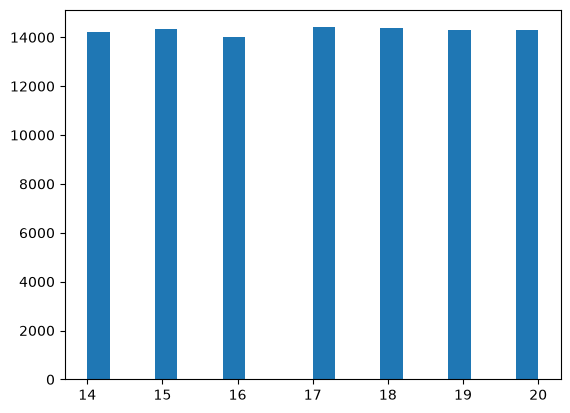

In [13]:
import matplotlib.pyplot as plt
plt.hist(data['age'],bins=20)

In [ ]:
print(data['age'].value_counts())
print('corr',data['age'].corr(data['exam_score']))  # Dropping the age column due to it have not no relationship with the exam score 

age
17    14406
18    14386
15    14324
20    14312
19    14310
14    14229
16    14033
Name: count, dtype: int64
corr -0.0034927096591034013


<Axes: xlabel='gender', ylabel='exam_score'>

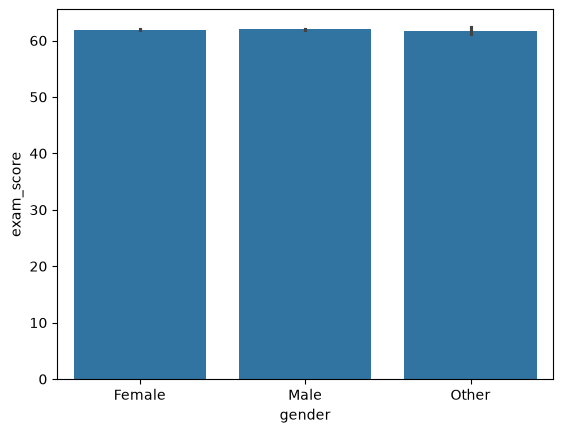

In [25]:
# %pip install seaborn
import seaborn as sns
sns.barplot(data=data, x='gender', y='exam_score')

In [27]:
data.groupby('gender')['exam_score'].mean()

gender
Female    61.946438
Male      61.961913
Other     61.750838
Name: exam_score, dtype: float64

In [30]:
print(data.groupby('education_level')['exam_score'].mean())
print(data['education_level'].value_counts())

education_level
High School      61.928094
Undergraduate    61.982702
Name: exam_score, dtype: float64
education_level
High School      59752
Undergraduate    40248
Name: count, dtype: int64


In [31]:
y=data['exam_score']

In [79]:
x=data
x

,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,...,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level
0,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,...,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39
1,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,...,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31
2,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,...,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87
3,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,...,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68
4,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,...,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,89.67,...,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36
99996,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,...,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68
99997,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,...,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97
99998,15,Female,High School,Private,High,Master,Rural,74.70,3.06,92.61,...,1,Shared,Moderate,0.55,Medium,28,93,81,100.00,10.00


In [76]:
# (data=='unknown').sum()

In [45]:
data.describe(include='number').columns
data.describe(exclude='number').columns

Index(['gender', 'education_level', 'school_type', 'family_income',
       'parent_education', 'urban_rural', 'class_participation',
       'study_consistency', 'study_environment', 'study_method',
       'revision_frequency', 'notes_quality', 'sleep_quality',
       'break_frequency', 'motivation_level', 'device_availability',
       'educational_app_usage', 'exam_difficulty'],
      dtype='str')

In [46]:
number=['age', 'previous_exam_score', 'previous_gpa', 'attendance_percentage',
       'assignment_completion_rate', 'study_hours_per_day', 'self_study_hours',
       'private_tuition', 'online_learning_hours', 'practice_tests_completed',
       'sleep_hours', 'daily_screen_time', 'physical_activity_hours',
       'stress_level', 'internet_access', 'online_course_hours',
       'exam_preparation_days', 'questions_attempted', 'questions_correct',
       'time_management_score', 'exam_anxiety_level']
catagory=['gender', 'education_level', 'school_type', 'family_income',
       'parent_education', 'urban_rural', 'class_participation',
       'study_consistency', 'study_environment', 'study_method',
       'revision_frequency', 'notes_quality', 'sleep_quality',
       'break_frequency', 'motivation_level', 'device_availability',
       'educational_app_usage', 'exam_difficulty']

<Axes: >

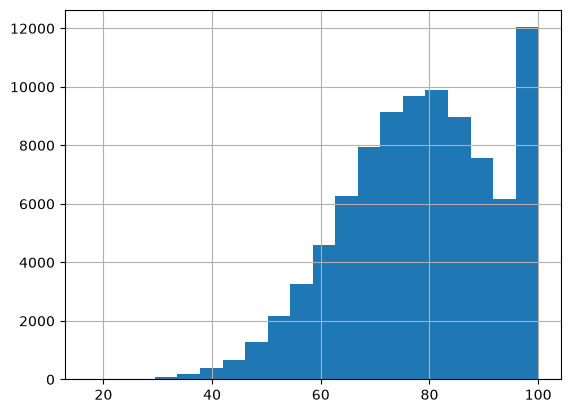

In [59]:
# data[number].isna().sum()
data['time_management_score'].hist(bins=20)


In [106]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print(x_train.shape,x_test.shape,y_train.shape,y_test.shape)

(80000, 39) (20000, 39) (80000,) (20000,)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (MinMaxScaler,StandardScaler,OneHotEncoder,FunctionTransformer,PowerTransformer)
from sklearn.pipeline import  Pipeline
from sklearn.compose import ColumnTransformer
from sklearn import set_config
set_config(transform_output='pandas')
number_cols=Pipeline([
    ('impuer',SimpleImputer(strategy='median')),
    ('transfor',PowerTransformer(method='yeo-johnson')),
    ('scalar',StandardScaler())
])

catagory_col=Pipeline([
    ('impuer',SimpleImputer(strategy='most_frequent')),
    ('ohencode',OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=int))
])

preprocessor=ColumnTransformer([
    ('number_cols',number_cols,['age', 'previous_exam_score', 'previous_gpa', 'attendance_percentage',
       'assignment_completion_rate', 'study_hours_per_day', 'self_study_hours',
       'private_tuition', 'online_learning_hours', 'practice_tests_completed',
       'sleep_hours', 'daily_screen_time', 'physical_activity_hours',
       'stress_level', 'internet_access', 'online_course_hours',
       'exam_preparation_days', 'questions_attempted', 'questions_correct',
       'time_management_score', 'exam_anxiety_level']),
    ('catagory_col',catagory_col,['gender', 'education_level', 'school_type', 'family_income',
       'parent_education', 'urban_rural', 'class_participation',
       'study_consistency', 'study_environment', 'study_method',
       'revision_frequency', 'notes_quality', 'sleep_quality',
       'break_frequency', 'motivation_level', 'device_availability',
       'educational_app_usage', 'exam_difficulty'])
],verbose_feature_names_out=False,remainder='passthrough')


x_train_final=preprocessor.fit_transform(x_train)
x_test_final=preprocessor.transform(x_test)



model=LinearRegression()
model.fit(x_train_final,y_train)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](80,)","[ 0.01, 0.28, 0. ,..., 0.29,-0.28,-0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](80,)","['age','previous_exam_score','previous_gpa',...,'exam_difficulty_Easy', 'exam_difficulty_Hard','exam_difficulty_Medium']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,61.92
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,80
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(62)


In [119]:
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,r2_score
pred_on_x_test = model.predict(x_test_final)
RMSE=root_mean_squared_error(y_test,pred_on_x_test)

In [123]:
r2=r2_score(y_test,pred_on_x_test)
print('r2_score',r2)
print('root_mean_squared_error',RMSE)

r2_score 0.9870795872606001
root_mean_squared_error 1.7921607163322857


In [126]:
PRED_ON_X_TRAIN=model.predict(x_train_final)
r2_score(y_train,PRED_ON_X_TRAIN)

0.9872943033734977

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'previous_exam_score'}>,
        <Axes: title={'center': 'previous_gpa'}>,
        <Axes: title={'center': 'attendance_percentage'}>,
        <Axes: title={'center': 'assignment_completion_rate'}>],
       [<Axes: title={'center': 'study_hours_per_day'}>,
        <Axes: title={'center': 'self_study_hours'}>,
        <Axes: title={'center': 'private_tuition'}>,
        <Axes: title={'center': 'online_learning_hours'}>,
        <Axes: title={'center': 'practice_tests_completed'}>],
       [<Axes: title={'center': 'sleep_hours'}>,
        <Axes: title={'center': 'daily_screen_time'}>,
        <Axes: title={'center': 'physical_activity_hours'}>,
        <Axes: title={'center': 'stress_level'}>,
        <Axes: title={'center': 'internet_access'}>],
       [<Axes: title={'center': 'online_course_hours'}>,
        <Axes: title={'center': 'exam_preparation_days'}>,
        <Axes: title={'center': 'questions_attempted'}>,


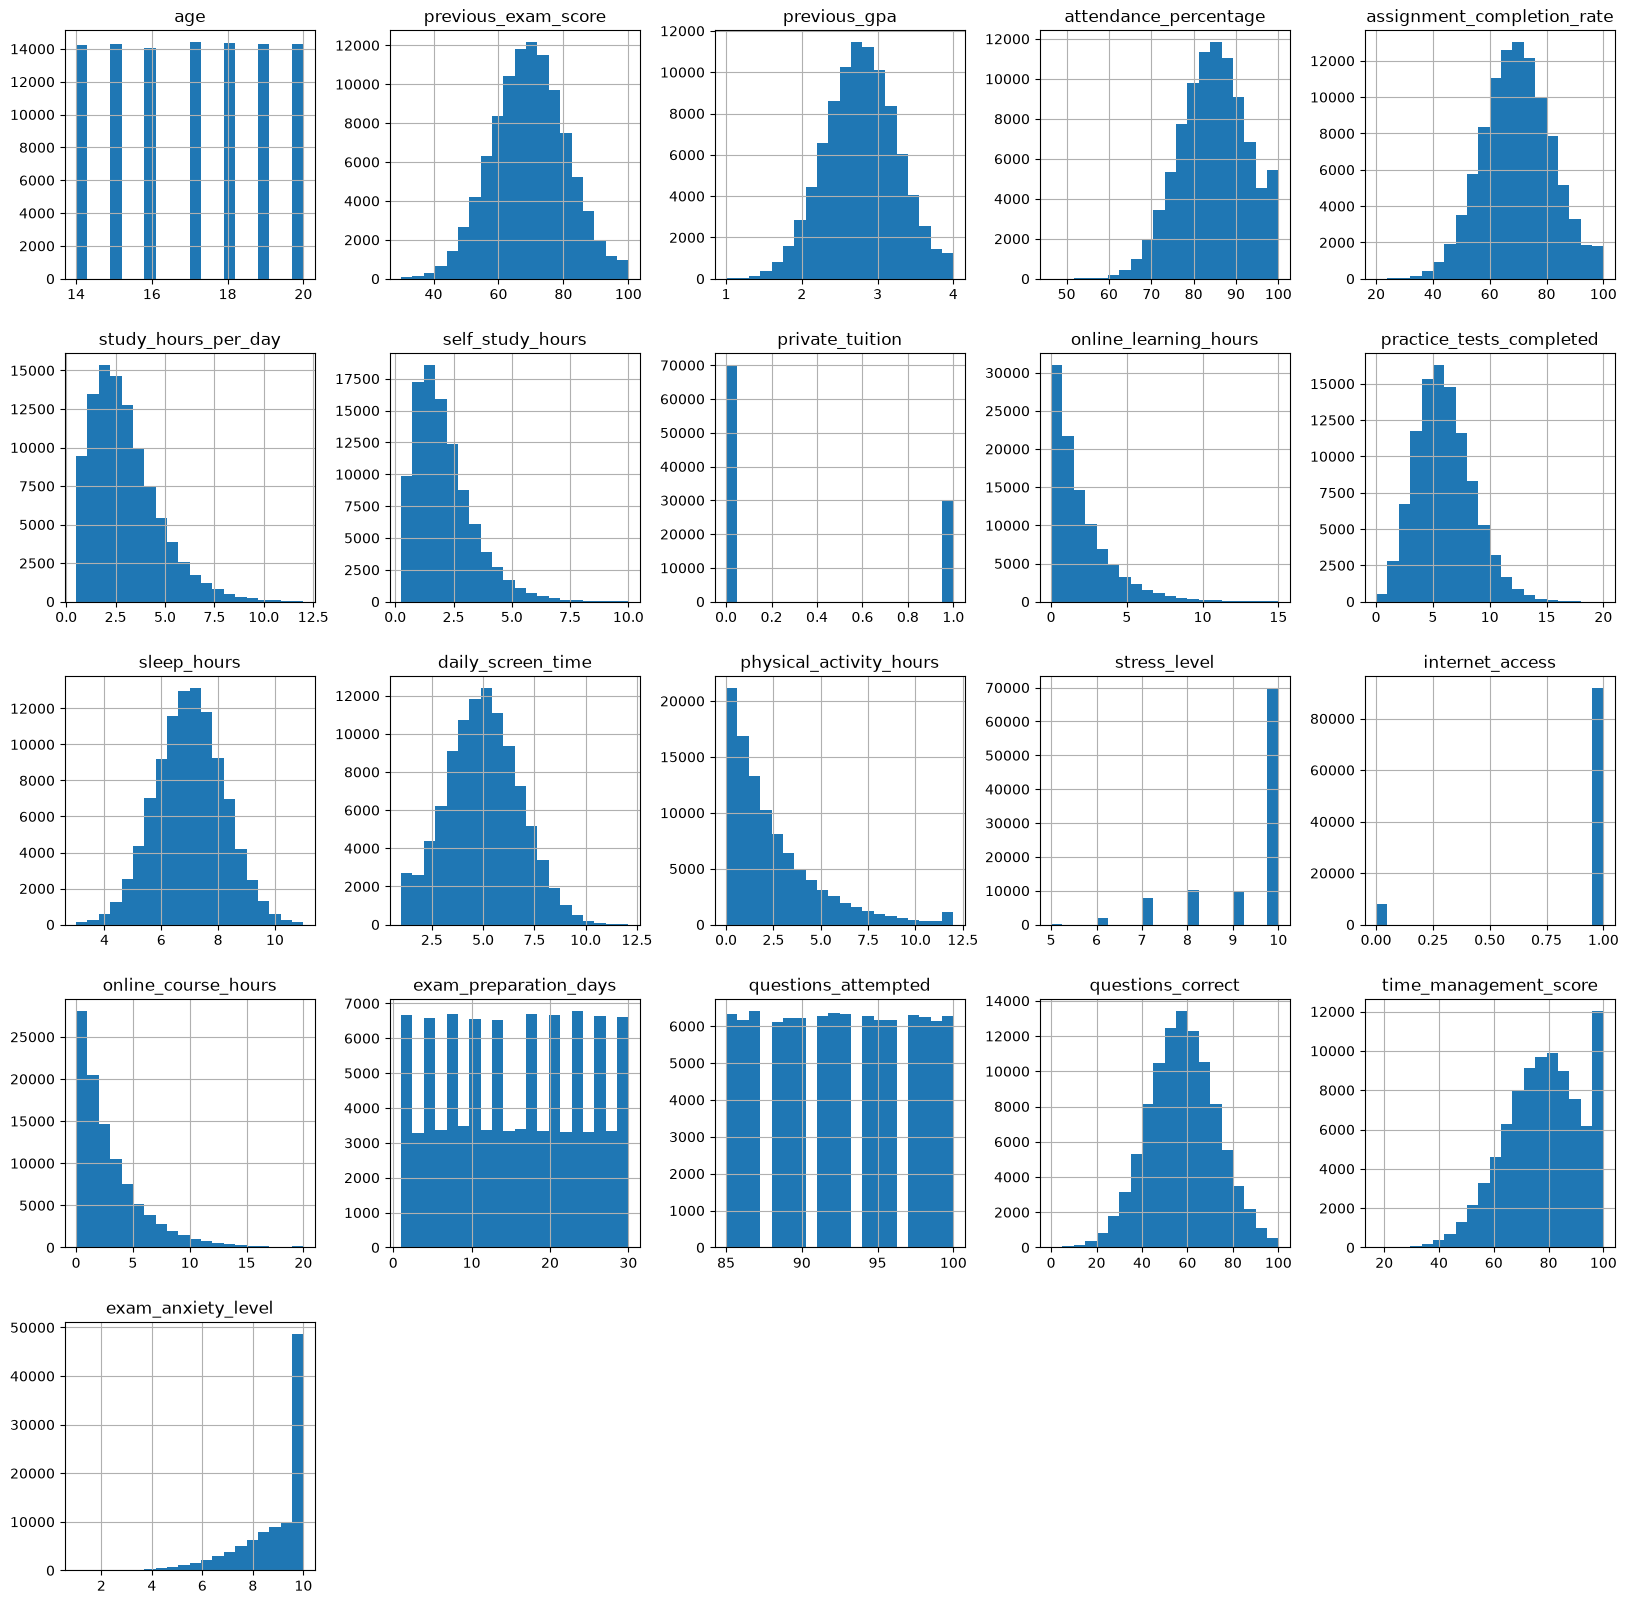

In [68]:
data.hist(bins=20,figsize=(20,20))

In [88]:
x_train['gender'].info()

<class 'pandas.Series'>
Index: 80000 entries, 75220 to 15795
Series name: gender
Non-Null Count  Dtype
--------------  -----
80000 non-null  str  
dtypes: str(1)
memory usage: 1.2 MB


In [131]:
x_train_final[number].corrwith(y_train)

age                          -0.002299
previous_exam_score           0.492565
previous_gpa                  0.447059
attendance_percentage         0.161446
assignment_completion_rate    0.222468
study_hours_per_day           0.355150
self_study_hours              0.337909
private_tuition               0.002972
online_learning_hours        -0.004256
practice_tests_completed      0.312306
sleep_hours                   0.172101
daily_screen_time             0.001996
physical_activity_hours       0.000362
stress_level                 -0.148747
internet_access               0.004516
online_course_hours          -0.003181
exam_preparation_days         0.212346
questions_attempted           0.005090
questions_correct             0.975372
time_management_score         0.102494
exam_anxiety_level           -0.117990
dtype: float64

In [133]:
x_train_final=x_train_final.drop(columns='questions_correct')

In [134]:
model.fit(x_train_final,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](79,)","[-0.05, 7.8 ,-0.11,..., 7.55,-7.52,-0.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](79,)","['age','previous_exam_score','previous_gpa',...,'exam_difficulty_Easy', 'exam_difficulty_Hard','exam_difficulty_Medium']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,61.92
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,79
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(61)


In [136]:
x_test_final=x_test_final.drop(columns='questions_correct')
prediction_2=model.predict(x_test_final)

In [142]:
print('r2_score_2',r2_score(y_test,prediction_2))
x_train_final_pred=model.predict(x_train_final)
print('r2_score_2 train data',r2_score(y_train,x_train_final_pred))

r2_score_2 0.6355168315376776
r2_score_2 train data 0.6396016767425561


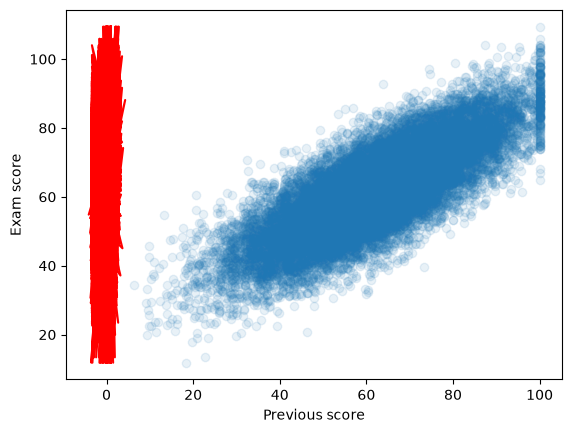

In [147]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


plt.scatter(y_test,prediction_2, alpha=0.1)
plt.plot(x_test_final,prediction_2 , color='red')
plt.xlabel('Previous score')
plt.ylabel('Exam score')
plt.show()

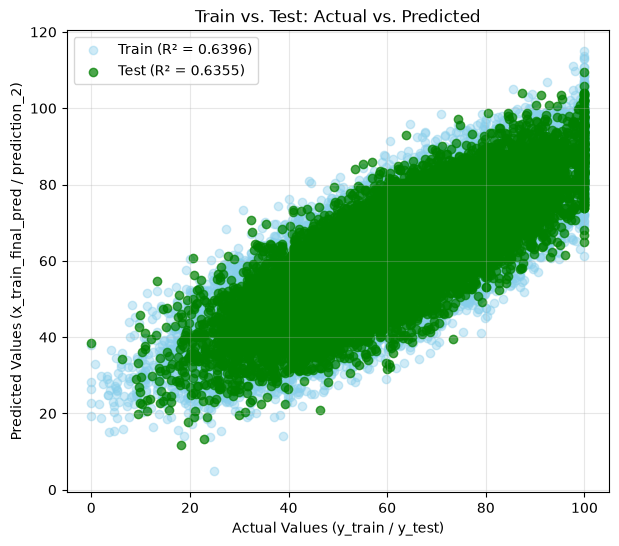

In [150]:
plt.figure(figsize=(7, 6))

# Plot Train predictions in light blue and Test predictions in orange
plt.scatter(y_train, x_train_final_pred, alpha=0.4, color='skyblue', label='Train (R² = 0.6396)')
plt.scatter(y_test, prediction_2, alpha=0.7, color='green', label='Test (R² = 0.6355)')


plt.title('Train vs. Test: Actual vs. Predicted')
plt.xlabel('Actual Values (y_train / y_test)')
plt.ylabel('Predicted Values (x_train_final_pred / prediction_2)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

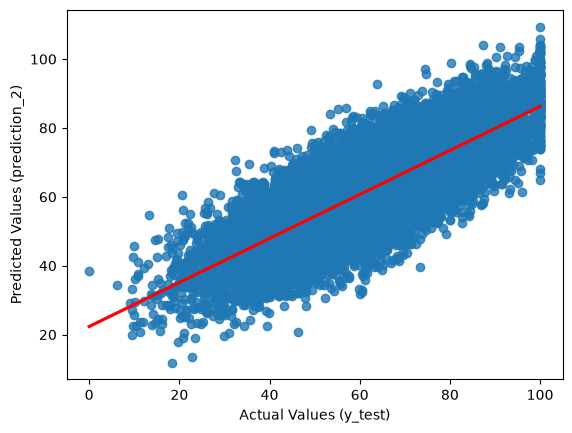

In [149]:
import matplotlib.pyplot as plt
import seaborn as sns

# Simple Actual (y_test) vs. Predicted (prediction_2) graph
sns.regplot(x=y_test, y=prediction_2, line_kws={'color': 'red'})
plt.xlabel('Actual Values (y_test)')
plt.ylabel('Predicted Values (prediction_2)')
plt.show()